# plot groundwater level

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [37]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

In [38]:
import numpy as np
import h5py as h5
import glob
import re
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.gridspec as gridspec
from datetime import datetime, timedelta
import pandas as pd

from shapely.geometry.polygon import Polygon
from shapely.geometry import Point
import shapefile

from natsort import natsorted, ns, natsort_keygen

from tqdm.notebook import tqdm
import pickle
import geopandas as gpd

from myfunc import batch_delta_to_time, print_structure
from fav_colors import turbo_colormap_data

from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset

In [39]:
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

In [40]:
import matplotlib
from matplotlib.colors import ListedColormap
#matplotlib.cm.register_cmap('turbo', cmap=ListedColormap(turbo_colormap_data))

# Check if 'turbo' colormap already exists
if not hasattr(matplotlib.cm, 'turbo'):
    # Register the new colormap
    matplotlib.cm.register_cmap('turbo', cmap=ListedColormap(turbo_colormap_data))
else:
    print("Colormap 'turbo' is already registered.")


Colormap 'turbo' is already registered.


# I/O files (Pin code)

In [5]:
#input
imodel = 'homo/'
# imodel = 'spinup-rerun/'

model_dir = "/global/cscratch1/sd/pshuai/HFR-thorne/" + imodel

# fname_model_origin = model_dir + "model_origin.txt"
fname_material_h5 = "/global/project/projectdirs/m1800/pin/HFR-thorne/meshes/Thorne-mesh-matID-river.h5"
fname_pflotran_h5 = model_dir + "HFR-model.h5"

data_dir = "/global/project/projectdirs/m1800/pin/Reach_scale_model/data/"

fname_mass1_coord = data_dir + "MASS1/coordinates.csv"
fname_river_geo = data_dir + "river_geometry_manual.csv"

fname_river_stage = "/global/project/projectdirs/m1800/pin/HFR-thorne/inputs/river_bc/stage_2007-2019/DatumH_River_321.txt"
#output
out_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/outputs/" + imodel

fig_wl = out_dir + 'wl/'

result_dir = "/global/project/projectdirs/m1800/pin/HFR-thorne/results/" + imodel

fname_centroid_p = '/global/project/projectdirs/m1800/pin/HFR-thorne/results/spinup/centroid.p'

fname_boundary_shp = "/global/project/projectdirs/m1800/pin/HFR-thorne/data/boundary_polygon_v3/boundary_polygon_v3.shp"
# output_dir = "/Users/song884/remote/reach/Outputs/HFR_100x100x5_6h_bc/"
# fig_dir = "/Users/song884/remote/reach/figures/HFR_100x100x5_6h_bc/wl/"
# data_dir = "/Users/song884/remote/reach/data/"

In [41]:
date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
# model_origin = [594140, 116060] 

In [42]:
P_atm = 101325
rho = 997.16
g_const = 9.81

## import h5

**get datetime**

In [75]:
# all_h5 = glob.glob(fname_pflotran_h5) # find all "pflotran*.h5" files
# all_h5 = np.sort(all_h5)

fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_iso_perm/HFR-iso-perm.h5'    # isotropic permeability model
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/perm_all_except_basalt.h5'              # anisotropic permeability model(except basalt)
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/perm_only_alluvium.h5'                  # anisotropic permeability model(only alluvium)

input_h5 = h5.File(fname_pflotran_h5, "r")
groups = list(input_h5.keys()) # create a list with group names
time_index = [s for s, s in enumerate(groups) if "Time" in s] # enumerate returns its index (index, string)
# list(input_h5.keys())
# sort time based on scientific value
time_index = sorted(time_index, key = lambda time: float(time.split(' ')[-2]))

real_time = [str(batch_delta_to_time(date_origin, [float(itime.split(' ')[-2])], "%Y-%m-%d %H:%M:%S", "hours")[0])
              for itime in time_index]

# real_time_sorted = natsorted(real_time)

In [44]:
input_h5[time_index[0]].visititems(print_structure)

Liquid Pressure [Pa]
Liquid Saturation
Liquid X-Velocity [m_per_h]
Liquid X-Velocity at cell face [m_per_h]
Liquid Y-Velocity [m_per_h]
Liquid Y-Velocity at cell face [m_per_h]
Liquid Z-Velocity [m_per_h]
Liquid Z-Velocity at cell face [m_per_h]
Material ID
Total Tracer_river [M]


### get mesh coordinates

In [10]:
#fname_centroid_p = '/global/homes/z/zc727/HFR/data/centroid.p'
#with open(fname_centroid_p, 'rb') as f:
#    centr, ele_per_layer = pickle.load(f)

In [45]:
import h5py
fname_material_h5 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID-river.h5'
mesh_h5 = h5.File(fname_material_h5, "r")

In [46]:
mesh_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Layer Ids
Materials/Material Ids
Regions
Regions/All
Regions/All/Cell Ids
Regions/Bottom
Regions/Bottom/Vertex Ids
Regions/Mass1_100
Regions/Mass1_100/Vertex Ids
Regions/Mass1_101
Regions/Mass1_101/Vertex Ids
Regions/Mass1_102
Regions/Mass1_102/Vertex Ids
Regions/Mass1_103
Regions/Mass1_103/Vertex Ids
Regions/Mass1_104
Regions/Mass1_104/Vertex Ids
Regions/Mass1_105
Regions/Mass1_105/Vertex Ids
Regions/Mass1_106
Regions/Mass1_106/Vertex Ids
Regions/Mass1_107
Regions/Mass1_107/Vertex Ids
Regions/Mass1_108
Regions/Mass1_108/Vertex Ids
Regions/Mass1_109
Regions/Mass1_109/Vertex Ids
Regions/Mass1_110
Regions/Mass1_110/Vertex Ids
Regions/Mass1_111
Regions/Mass1_111/Vertex Ids
Regions/Mass1_112
Regions/Mass1_112/Vertex Ids
Regions/Mass1_113
Regions/Mass1_113/Vertex Ids
Regions/Mass1_114
Regions/Mass1_114/Vertex Ids
Regions/Mass1_115
Regions/Mass1_115/Vertex Ids
Regions/Mass1_116
Regions/Mass1_116/Vertex Ids
Regions/Mas

In [47]:
vert_bot = np.array(mesh_h5['Regions/Bottom/Vertex Ids'])

ele_per_layer = vert_bot.shape[0]

vert_coord = np.array(mesh_h5['Domain/Vertices'][:]) # eg. x_coord, y_coord, z_coord
cell_vert = np.array(mesh_h5['Domain/Cells'][:]) # eg. node#, node1, node2, node3, node4, node5, node6...

centr = []
for i in np.arange(cell_vert.shape[0])[:]:

    ivert_id = cell_vert[i, 1:] # vertice id is 1-based
    ivert_coord = vert_coord[ivert_id-1, :]  
    
    icentr = ivert_coord[:, 0].mean(), ivert_coord[:, 1].mean(), ivert_coord[:, 2].mean()
    centr.append(icentr)

centr = np.asarray(centr)

In [48]:
mesh_h5.close()

In [13]:
fname_centroid_p = '/global/homes/z/zc727/HFR/data/centroid.p'
with open(fname_centroid_p, 'wb') as f:
    pickle.dump([centr, ele_per_layer], f, protocol=-1)

## import river stage

In [49]:
fname_river_stage = '/global/homes/z/zc727/HFR/data/stage_2007-2019/DatumH_River_321.txt'
river_stage = pd.read_csv(fname_river_stage, header = None, sep = " ", 
                          names= ['dt', 'Easting', 'Northing', 'wl'])
river_stage['datetime'] = [date_origin + timedelta(seconds = i) for i in river_stage['dt'].values]
river_stage.set_index('datetime', drop = False, inplace = True)

## set mask

Approach follows this [post](https://stackoverflow.com/questions/42426095/matplotlib-contour-contourf-of-concave-non-gridded-data). The key is to create a mask with `0` indicates cells inside polygon and `1` indicated cells outside polygon.

In [50]:
fname_boundary_shp = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/shapefile/boundary_poly_v5.shp'
bnd_shapefile = shapefile.Reader(fname_boundary_shp) 
bnd_shapefile = bnd_shapefile.shapes() 
shpfilePoints = [shape.points for shape in bnd_shapefile]
bnd_polygons = shpfilePoints

In [51]:
bndPoly = Polygon(bnd_polygons[0]) # in this case, only one polygon presents

In [52]:
x = centr[-ele_per_layer:,0]
y = centr[-ele_per_layer:,1]

In [53]:
triang = tri.Triangulation(x, y)
# set mask
x2 = x[triang.triangles].mean(axis=1) 
y2 = y[triang.triangles].mean(axis=1)

boolean_list = [bndPoly.contains(Point(ix, iy)) for ix,iy in zip(x2,y2)]
mask = np.where(boolean_list, 0, 1)

In [54]:
# apply masking
triang.set_mask(mask)

# plot GW level contour

In [20]:
print(np.shape(centr))
print(ele_per_layer)

(902937, 3)
29127


In [25]:
# %matplotlib inline
boundary_shape=gpd.read_file(fname_boundary_shp)

In [36]:
print(type(time_index))

<class 'list'>


  0%|          | 0/1 [00:00<?, ?it/s]

/tmp/ipykernel_1251554/114665008.py:65: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


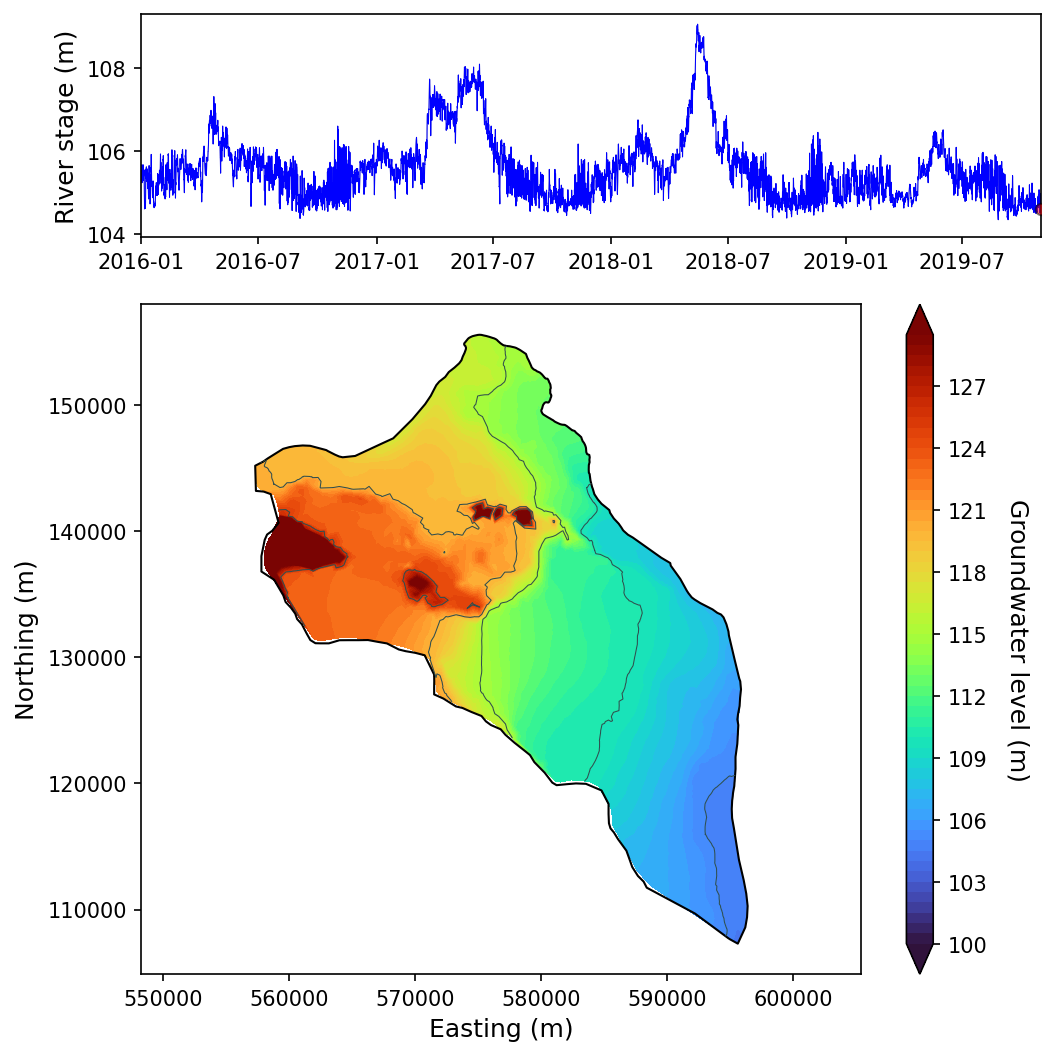

In [77]:
for itime in tqdm(real_time[-1::]):  # Use [657::] or [831:832]
    ind = real_time.index(itime)
    itimestep = time_index[ind]

    # compute pressure head to total head
    temp_pressure = np.array(input_h5[itimestep]["Liquid Pressure [Pa]"])
    temp_head = (temp_pressure - P_atm) / rho / g_const
    temp_wl = temp_head + centr[:, 2]

    # get the total head on the bottom layer
    temp_wl_coord = np.column_stack((centr[-ele_per_layer:, 0:2], temp_wl[-ele_per_layer:]))
    
    fig = plt.figure()
    gs = gridspec.GridSpec(2, 1, height_ratios=[1, 3])
    gs.update(left=0.15, right=0.9, top=0.9, bottom=0.1, hspace=0.15)
    
    ax1 = plt.subplot(gs[0])
    ax2 = plt.subplot(gs[1])
    
    # Plotting river stage (common in both code snippets)
    ax1.plot(river_stage.datetime, river_stage.wl, lw=0.5, color='gray', alpha=0.5, zorder=1)
    data = river_stage.loc[:itime, :]
    ax1.plot(data.datetime, data.wl, lw=0.5, color='b', alpha=1, zorder=2)
    ax1.scatter(river_stage.loc[itime, 'datetime'], river_stage.loc[itime, 'wl'],
                facecolors='red', edgecolors='black', s=30, alpha=0.5, zorder=3)
    ax1.set_ylabel('River stage (m)', fontsize=12)
    ax1.set_xlim(['01/01/2016', '11/01/2019'])
    
    # Adjust z and contours to mimic Code B style
    z = temp_wl_coord[:, 2]
    cf1 = ax2.tricontour(triang, z, levels=np.arange(100, 130, 5), linewidths=0.5, colors='darkslategray')
    cf2 = ax2.tricontourf(triang, z, levels=np.arange(100, 130, 0.5), extend="both", cmap="turbo")
    
    ax2.set_xlabel("Easting (m)", fontsize=12)
    ax2.set_ylabel("Northing (m)", fontsize=12)
    ax2.set_aspect("equal", "datalim")
    
    cb1 = plt.colorbar(cf2, extend="both", spacing="uniform", orientation="vertical", shrink=1, aspect=25)
    cb1.ax.set_ylabel("Groundwater level (m)", rotation=270, labelpad=20, fontsize=12)
    
    # Boundary plot replication if necessary
    boundary_shape.plot(facecolor='none', edgecolor='black', ax=ax2, alpha=1)
    
    # Adding inset plot for Code A to match Code B if necessary
    #a = plt.axes([0.17, 0.05, 0.4, 0.38])  # Position for inset
    #mark_inset(ax2, a, loc1=1, loc2=2, fc="none", ec="black")
    #a.tricontour(triang, z, levels=np.arange(100, 130, 5), linewidths=0.5, colors='darkslategray')
    #a.tricontourf(triang, z, levels=np.arange(100, 130, 0.5), extend="both", cmap="turbo")
    #boundary_shape.plot(facecolor='none', edgecolor='gray', ax=a, alpha=1)
    
    # north horn
    #block1_x = np.array([560000, 571600])
    #block1_y = np.array([132500, 142500])
    
    #a.set_xlim(block1_x)
    #a.set_ylim(block1_y)
    
    #a.set_aspect("equal")
    #ax1.set_title(itime, fontsize=14)
    #a.tick_params(axis='both', left=False, top=False, right=False, bottom=False,
    #              labelleft=False, labeltop=False, labelright=False, labelbottom=False)
    
    fig.set_size_inches(8, 8)
    
    plt.tight_layout()
    plt.show()
    
    #fig_wl = '/pscratch/sd/z/zc727/OUTPUT/GWtable/perm_only_alluvium/'           # change the folder at here
    #fig_name = fig_wl + "wl_" + str(ind) + ".png"
    #fig.savefig(fig_name, dpi=300, transparent=False)
    #plt.close(fig)    